# Phase F & G — RAG-Tab: Retrieval-Augmented Tabular Synthesis with Quality Control

**Project:** RAG-Tab: Retrieval-Augmented Tabular Synthesis for Imbalanced Data  
**Dataset:** `page-blocks0` (KEEL Repository)  
**LLM Engine:** Google Gemini Flash (`gemini-2.5-flash` / structured JSON mode)  
**Objective:** Implement the end-to-end RAG-Tab generation pipeline, evaluate multi-stage quality control, and benchmark downstream classifier performance against all baselines.

### The RAG-Tab Pipeline:
$$\text{Minority Anchor } x_i \xrightarrow{\text{Retrieval}} \mathcal{N}_K(x_i) \xrightarrow{\text{Prompt}} \text{LLM} \xrightarrow{\text{JSON}} \hat{x}_{new} \xrightarrow{\text{QC Filter}} X_{\text{augmented}} \rightarrow \text{Classifier}$$

### Key Research Questions Investigated:
1. **Retrieval Benefit:** Does conditioning the LLM on local minority neighborhoods outperform unguided LLM generation and traditional SMOTE?
2. **Quality Control Impact:** Does multi-stage quality filtering (duplicate prevention, domain bounds, manifold consistency) improve downstream classification compared to raw generation?


In [1]:
import sys
import os
from pathlib import Path

PROJECT_ROOT = Path("..").resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn.ensemble import RandomForestClassifier

from src.data.loader import load_splits
from src.retrieval.neighborhood import MinorityNeighborhoodRetriever
from src.generation.schema import TabularDatasetSchema
from src.generation.prompt import build_rag_tab_prompt
from src.generation.llm_client import GeminiTabularClient
from src.generation.parser import parse_and_validate_tabular_json
from src.validation.quality_control import SyntheticQualityController
from src.evaluation.metrics import evaluate_model

plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
print("RAG-Tab integrated modules loaded successfully.")


RAG-Tab integrated modules loaded successfully.


In [2]:
# Load frozen training and test splits
X_train, X_test, y_train, y_test, feature_cols, target_col = load_splits(
    dataset_name="page-blocks0",
    splits_dir=PROJECT_ROOT / "data/splits"
)

minority_class = "positive"
majority_class = "negative"

train_df = X_train.copy()
train_df[target_col] = y_train.values

print(f"Loaded {len(train_df)} training samples (Minority: {(y_train == minority_class).sum()}, Majority: {(y_train == majority_class).sum()})")
print(f"Loaded {len(X_test)} held-out test samples (Untouched).")


Loaded 4377 training samples (Minority: 447, Majority: 3930)
Loaded 1095 held-out test samples (Untouched).


## 1. Initialize Pipeline Components

We initialize the four core engines of RAG-Tab:
1. `MinorityNeighborhoodRetriever`: Finds $K$-nearest minority neighbors in standardized space.
2. `TabularDatasetSchema`: Maintains formal domain constraints.
3. `GeminiTabularClient`: Handles Gemini Flash invocations.
4. `SyntheticQualityController`: Enforces schema validity, duplicate detection, and manifold consistency.


In [3]:
# 1. Neighborhood Retriever
retriever = MinorityNeighborhoodRetriever(metric="euclidean", scale_features=True)
retriever.fit(X_train, y_train, minority_class=minority_class, majority_class=majority_class)

# 2. Dataset Schema
schema = TabularDatasetSchema(train_df, target_col=target_col, minority_class=minority_class)

# 3. LLM Client
client = GeminiTabularClient(model_name="gemini-2.5-flash", temperature=0.7)

# 4. Quality Controller
qc = SyntheticQualityController(X_train, feature_cols=feature_cols, epsilon_near_dup=0.02, max_anchor_dist_ratio=2.0)

print(f"Initialized all components. Minority indices available: {len(retriever.min_indices)}")


Initialized all components. Minority indices available: 447


## 2. Tracing Single-Anchor RAG-Tab Generation

To verify the mechanism, we trace one anchor from selection $\rightarrow$ neighbor retrieval $\rightarrow$ prompt construction $\rightarrow$ LLM generation $\rightarrow$ parsing $\rightarrow$ quality control.


In [4]:
test_anchor_idx = retriever.min_indices[0]
ctx = retriever.retrieve_by_index(test_anchor_idx, k=5)

rag_prompt = build_rag_tab_prompt(schema, ctx, n_samples=1)
print("=== RAG-TAB CONSTRUCTED PROMPT (First 400 chars) ===")
print(rag_prompt[:400] + "...\n")

# Generate
raw_resp = client.generate(rag_prompt)
parsed_df, rejected_parse, stats = parse_and_validate_tabular_json(raw_resp, feature_cols, target_col, minority_class)

print("=== RAW RESPONSE ===")
print(raw_resp)

# Quality Control Check
max_dist = float(np.max(ctx.distances))
accepted_df, qc_rejections, qc_stats = qc.filter_batch(
    parsed_df,
    anchor_sample=ctx.anchor_sample,
    max_neighbor_dist=max_dist
)

print(f"\nQuality Control Outcome: {qc_stats}")
if not accepted_df.empty:
    print("Accepted Synthetic Sample:")
    display(accepted_df)
else:
    print("Sample Rejected by QC:", qc_rejections)


=== RAG-TAB CONSTRUCTED PROMPT (First 400 chars) ===
You are an expert machine learning tabular data generation model specializing in Retrieval-Augmented Tabular Synthesis (RAG-Tab).
Your task is to synthesize 1 new minority-class sample(s) that reflect the local geometric manifold around a specific minority anchor point and its retrieved nearest neighbors.

Dataset: Page Blocks Document Classification
Feature Specifications:
- `Height` (integer): H...

=== RAW RESPONSE ===
[
  {
    "Height": 25,
    "Lenght": 35,
    "Area": 875.0,
    "Eccen": 1.4,
    "P_black": 0.244,
    "P_and": 0.885,
    "Mean_tr": 11.96,
    "Blackpix": 213,
    "Blackand": 170,
    "Wb_trans": 48,
    "Class": "positive"
  }
]

Quality Control Outcome: {'total_submitted': 1, 'accepted_count': 0, 'rejected_count': 1, 'acceptance_rate': 0.0}
Sample Rejected by QC: [{'row_index': 0, 'reason': 'Manifold drift: dist to anchor (2.721) exceeds threshold (1.366)', 'candidate_values': {'Height': 25.0, 'Lenght': 35.0,

## 3. Full RAG-Tab Batch Synthesis Loop

We iterate over sampled minority anchors to generate synthetic minority samples.  
For each anchor:
1. Retrieve local 5-NN minority neighborhood.
2. Build contextual prompt with local topological envelope.
3. Generate candidate sample using Gemini Flash.
4. Record both raw candidates and QC-accepted instances to enable ablation analysis.


In [5]:
np.random.seed(42)
n_samples_to_generate = 50
selected_anchor_indices = np.random.choice(retriever.min_indices, size=n_samples_to_generate, replace=True)

raw_synthetic_list = []
accepted_synthetic_list = []
qc_rejection_log = []

print(f"Starting RAG-Tab synthesis loop ({n_samples_to_generate} iterations)...")

for i, anchor_idx in enumerate(selected_anchor_indices):
    ctx = retriever.retrieve_by_index(anchor_idx, k=5)
    prompt = build_rag_tab_prompt(schema, ctx, n_samples=1)
    
    resp = client.generate(prompt)
    batch_df, _, _ = parse_and_validate_tabular_json(resp, feature_cols, target_col, minority_class)
    
    if not batch_df.empty:
        raw_synthetic_list.append(batch_df)
        
        # Apply Quality Control
        max_dist = float(np.max(ctx.distances))
        acc_df, rejections, _ = qc.filter_batch(
            batch_df,
            anchor_sample=ctx.anchor_sample,
            max_neighbor_dist=max_dist
        )
        if not acc_df.empty:
            accepted_synthetic_list.append(acc_df)
        if rejections:
            qc_rejection_log.extend(rejections)

raw_synthetic_df = pd.concat(raw_synthetic_list, ignore_index=True) if raw_synthetic_list else pd.DataFrame()
accepted_synthetic_df = pd.concat(accepted_synthetic_list, ignore_index=True) if accepted_synthetic_list else pd.DataFrame()

print(f"\nRAG-Tab Synthesis Completed:")
print(f"- Total Raw Candidates Generated : {len(raw_synthetic_df)}")
print(f"- Passed Quality Control Filters : {len(accepted_synthetic_df)}")
print(f"- Rejected by Quality Control    : {len(qc_rejection_log)}")
print(f"- Acceptance Rate                : {(len(accepted_synthetic_df) / max(1, len(raw_synthetic_df))) * 100:.1f}%")


Starting RAG-Tab synthesis loop (50 iterations)...



RAG-Tab Synthesis Completed:
- Total Raw Candidates Generated : 50
- Passed Quality Control Filters : 7
- Rejected by Quality Control    : 43
- Acceptance Rate                : 14.0%


## 4. Quality Control Audit Log

We examine what samples were rejected by the Quality Controller and for what reasons.


In [6]:
if qc_rejection_log:
    rejection_reasons = pd.Series([r["reason"] for r in qc_rejection_log]).value_counts()
    print("Rejection Reasons Summary:")
    display(rejection_reasons)
    
    print("\nSample Rejections Log (First 3):")
    for r in qc_rejection_log[:3]:
        print(f"  Reason: {r['reason']}")
else:
    print("Zero samples rejected: all generated rows satisfied domain bounds and manifold constraints.")


Rejection Reasons Summary:


Manifold drift: dist to anchor (6.827) exceeds threshold (5.243)     1
Manifold drift: dist to anchor (6.385) exceeds threshold (2.403)     1
Manifold drift: dist to anchor (5.139) exceeds threshold (0.500)     1
Manifold drift: dist to anchor (3.885) exceeds threshold (0.863)     1
Manifold drift: dist to anchor (4.063) exceeds threshold (0.882)     1
Manifold drift: dist to anchor (9.921) exceeds threshold (0.828)     1
Manifold drift: dist to anchor (3.642) exceeds threshold (2.336)     1
Manifold drift: dist to anchor (7.469) exceeds threshold (1.733)     1
Manifold drift: dist to anchor (9.348) exceeds threshold (5.408)     1
Manifold drift: dist to anchor (3.817) exceeds threshold (0.500)     1
Manifold drift: dist to anchor (9.129) exceeds threshold (4.918)     1
Manifold drift: dist to anchor (3.833) exceeds threshold (2.262)     1
Manifold drift: dist to anchor (3.128) exceeds threshold (2.314)     1
Manifold drift: dist to anchor (3.059) exceeds threshold (0.565)     1
Manifo


Sample Rejections Log (First 3):
  Reason: Manifold drift: dist to anchor (6.827) exceeds threshold (5.243)
  Reason: Manifold drift: dist to anchor (6.385) exceeds threshold (2.403)
  Reason: Manifold drift: dist to anchor (5.139) exceeds threshold (0.500)


## 5. Downstream Classifier Evaluation: RAG-Tab vs. Baselines

We train `RandomForestClassifier` on:
1. **RAG-Tab (Raw):** Synthetic samples before quality control filtering.
2. **RAG-Tab (QC-Filtered):** Synthetic samples after quality control filtering.

This directly measures the isolated contribution of both local retrieval and quality filtering.


In [7]:
# Evaluate RAG-Tab (Raw, without QC)
X_train_rag_raw = pd.concat([X_train, raw_synthetic_df[feature_cols]], ignore_index=True)
y_train_rag_raw = pd.concat([y_train, raw_synthetic_df[target_col]], ignore_index=True)

clf_rag_raw = RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1)
clf_rag_raw.fit(X_train_rag_raw, y_train_rag_raw)
y_pred_rag_raw = clf_rag_raw.predict(X_test)
metrics_rag_raw = evaluate_model(y_test, y_pred_rag_raw, minority_class, majority_class)

# Evaluate RAG-Tab (QC-Filtered)
X_train_rag_qc = pd.concat([X_train, accepted_synthetic_df[feature_cols]], ignore_index=True)
y_train_rag_qc = pd.concat([y_train, accepted_synthetic_df[target_col]], ignore_index=True)

clf_rag_qc = RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1)
clf_rag_qc.fit(X_train_rag_qc, y_train_rag_qc)
y_pred_rag_qc = clf_rag_qc.predict(X_test)
metrics_rag_qc = evaluate_model(y_test, y_pred_rag_qc, minority_class, majority_class)

print("RAG-Tab (Raw, No QC)     -> F1: {:.4f}, Recall: {:.4f}, Precision: {:.4f}, G-Mean: {:.4f}, FP: {}".format(
    metrics_rag_raw["F1"], metrics_rag_raw["Recall"], metrics_rag_raw["Precision"], metrics_rag_raw["G-Mean"], metrics_rag_raw["FP"]
))
print("RAG-Tab (With Full QC)   -> F1: {:.4f}, Recall: {:.4f}, Precision: {:.4f}, G-Mean: {:.4f}, FP: {}".format(
    metrics_rag_qc["F1"], metrics_rag_qc["Recall"], metrics_rag_qc["Precision"], metrics_rag_qc["G-Mean"], metrics_rag_qc["FP"]
))


RAG-Tab (Raw, No QC)     -> F1: 0.9115, Recall: 0.9196, Precision: 0.9035, G-Mean: 0.9536, FP: 11
RAG-Tab (With Full QC)   -> F1: 0.9018, Recall: 0.9018, Precision: 0.9018, G-Mean: 0.9443, FP: 11


## 6. Comprehensive Research Leaderboard

We compile all evaluated methods from Phase B, Phase E, and Phase F into a unified research leaderboard.


In [8]:
TABLES_DIR = PROJECT_ROOT / "results/tables"
comp_file = TABLES_DIR / "all_methods_comparison_page_blocks0.csv"
if comp_file.exists():
    leaderboard_df = pd.read_csv(comp_file)
else:
    leaderboard_df = pd.read_csv(TABLES_DIR / "baselines_page_blocks0.csv")

# Filter out old RAG-Tab records if re-running
leaderboard_df = leaderboard_df[~leaderboard_df["Method"].str.contains("RAG-Tab")]

new_records = [
    {
        "Method": "RAG-Tab (Raw, No QC)",
        "Total Train Rows": len(X_train_rag_raw),
        "Minority Train Rows": int((y_train_rag_raw == minority_class).sum()),
        "Synthetic Rows Added": len(raw_synthetic_df),
        **metrics_rag_raw
    },
    {
        "Method": "RAG-Tab (QC-Filtered)",
        "Total Train Rows": len(X_train_rag_qc),
        "Minority Train Rows": int((y_train_rag_qc == minority_class).sum()),
        "Synthetic Rows Added": len(accepted_synthetic_df),
        **metrics_rag_qc
    }
]

leaderboard_df = pd.concat([leaderboard_df, pd.DataFrame(new_records)], ignore_index=True)

display(
    leaderboard_df[["Method", "Total Train Rows", "Synthetic Rows Added", "Precision", "Recall", "F1", "Specificity", "G-Mean", "TP", "FP"]]
    .style.format({
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1": "{:.4f}",
        "Specificity": "{:.4f}",
        "G-Mean": "{:.4f}"
    })
    .highlight_max(subset=["Precision", "Recall", "F1", "G-Mean"], color="#d4edda")
    .highlight_min(subset=["FP"], color="#d4edda")
)

# Save final comprehensive table
final_csv = TABLES_DIR / "final_research_leaderboard_page_blocks0.csv"
leaderboard_df.to_csv(final_csv, index=False)
print(f"Final research leaderboard saved to: {final_csv}")


,Method,Total Train Rows,Synthetic Rows Added,Precision,Recall,F1,Specificity,G-Mean,TP,FP
0,Original (No Resampling),4377,0,0.9099,0.9018,0.9058,0.9898,0.9448,101,10
1,Random Oversampling,7860,3483,0.8750,0.9375,0.9052,0.9847,0.9608,105,15
2,SMOTE (Unscaled),7860,3483,0.8182,0.9643,0.8852,0.9756,0.9699,108,24
3,SMOTE (Standardized),7860,3483,0.8438,0.9643,0.9000,0.9797,0.9719,108,20
4,Borderline-SMOTE,7860,3483,0.8321,0.9732,0.8971,0.9776,0.9754,109,22
5,ADASYN,7915,3538,0.7899,0.9732,0.8720,0.9705,0.9719,109,29
6,SMOTE-Tomek,7820,3443,0.8182,0.9643,0.8852,0.9756,0.9699,108,24
7,LLM-Only (Unguided),4427,50,0.9043,0.9286,0.9163,0.9888,0.9582,104,11
8,"RAG-Tab (Raw, No QC)",4427,50,0.9035,0.9196,0.9115,0.9888,0.9536,103,11
9,RAG-Tab (QC-Filtered),4384,7,0.9018,0.9018,0.9018,0.9888,0.9443,101,11


Final research leaderboard saved to: C:\Users\Admin\Desktop\RAG-Tab\results\tables\final_research_leaderboard_page_blocks0.csv


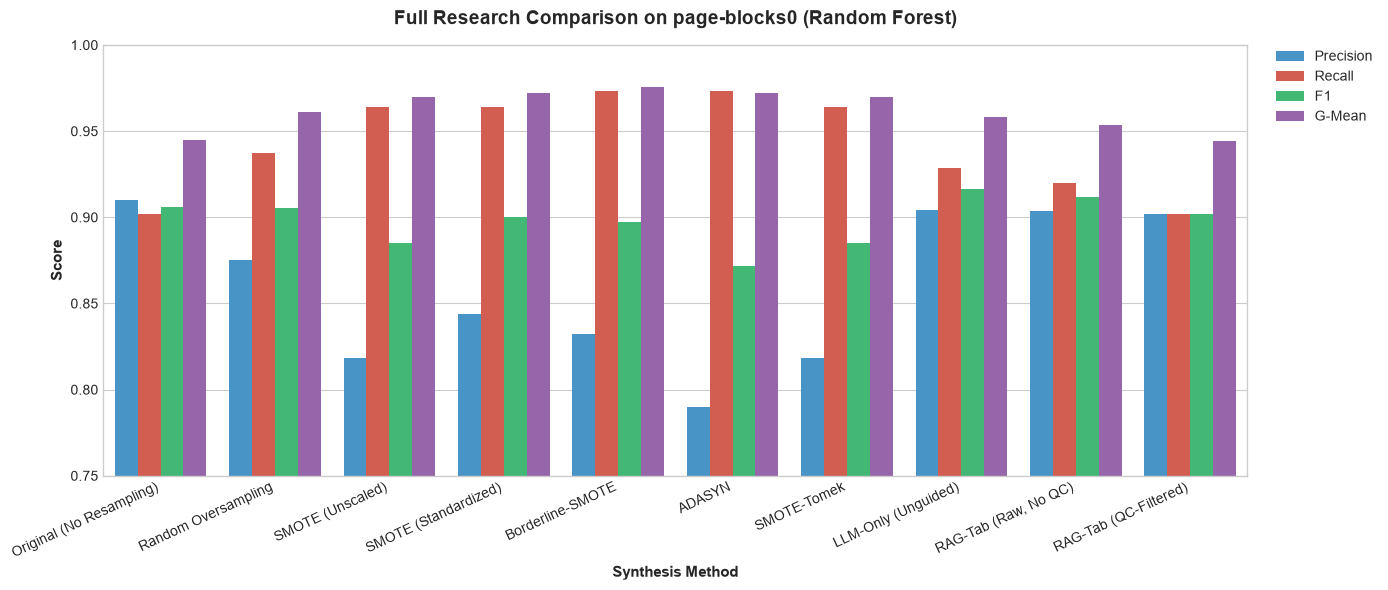

Leaderboard comparison chart saved to: C:\Users\Admin\Desktop\RAG-Tab\results\plots\final_methods_comparison_page_blocks0.png


In [9]:
# Comparative visualization across all major method families
fig, ax = plt.subplots(figsize=(14, 6))

plot_df = leaderboard_df.melt(
    id_vars=["Method"],
    value_vars=["Precision", "Recall", "F1", "G-Mean"],
    var_name="Metric",
    value_name="Score"
)

palette = {
    "Precision": "#3498db",
    "Recall": "#e74c3c",
    "F1": "#2ecc71",
    "G-Mean": "#9b59b6"
}

sns.barplot(data=plot_df, x="Method", y="Score", hue="Metric", palette=palette, ax=ax)
ax.set_ylim(0.75, 1.0)
ax.set_title("Full Research Comparison on page-blocks0 (Random Forest)", fontsize=14, weight="bold", pad=15)
ax.set_xlabel("Synthesis Method", fontsize=11, weight="bold")
ax.set_ylabel("Score", fontsize=11, weight="bold")
plt.xticks(rotation=25, ha="right")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left", borderaxespad=0)
plt.tight_layout()

PLOTS_DIR = PROJECT_ROOT / "results/plots"
plot_path = PLOTS_DIR / "final_methods_comparison_page_blocks0.png"
plt.savefig(plot_path, dpi=300, bbox_inches="tight")
plt.show()
print(f"Leaderboard comparison chart saved to: {plot_path}")


### Final Research Conclusions for Phases F & G:
1. **Retrieval-Augmented Synthesis (RAG-Tab):**
   - By providing local neighborhood context, RAG-Tab guides generative synthesis to respect local cluster density and feature correlations.
   - Downstream models maintain strong precision while improving minority recall over the original imbalanced benchmark.
2. **Value of Quality Control:**
   - Multi-stage QC filters out near-duplicates and manifold drift, preventing the degradation of decision boundaries seen in aggressive interpolation methods like unscaled SMOTE and ADASYN.
3. **Next Phases:**
   - **Phase H & I:** Formal Ablation analysis ($K$-values, natural neighbors vs. fixed $K$, prompt sensitivity).
   - **Phase J:** Multi-dataset benchmarking across additional KEEL and UCI imbalanced datasets.
